[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/danpele/Blockchain-Applications/blob/main/Quantlets/L5/BA_L5_acf/BA_L5_acf.ipynb)

# BA_L5_acf: Duration of Peg Deviations

*Quantlet of Lecture 5, Blockchain Applications. Daniel Traian Pele, Bucharest University of Economic Studies.*

Autocorrelation function, lags 1 to 30 days, of the daily close deviations of USDT, USDC and DAI from the 1 USD peg, 1 January 2021 to 23 October 2026, with the band of no autocorrelation at the 5% level. Data: EODHD daily aggregated prices.

In [1]:
OUT_DIR = '.'
SAVE_TO_DRIVE = False

In [2]:
import os
import tempfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')
pd.set_option('display.width', 160)
pd.set_option('display.max_columns', 30)

# Chart style: transparent background, legend below the plot, no grey
plt.rcParams.update({
    'figure.facecolor': 'none', 'axes.facecolor': 'none', 'savefig.facecolor': 'none', 'savefig.transparent': True,
    'axes.grid': False, 'font.size': 11, 'axes.labelsize': 12, 'axes.titlesize': 12,
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.linewidth': 0.6, 'lines.linewidth': 1.3,
    'legend.facecolor': 'none', 'legend.framealpha': 0, 'legend.fontsize': 10,
})

# Chart colours (the same as in the slides)
BTC, ETH, BLUE, GOLD, RED, GREEN = '#E8913A', '#9B59B6', '#1A3A6E', '#B5853F', '#CD0000', '#2E7D32'
ORANGE, PURPLE, NAVY, TEAL = '#E67E22', '#8E44AD', '#1F2A44', '#17A2B8'

# outputs go to OUT_DIR (Google Drive) if SAVE_TO_DRIVE = True, otherwise to a temporary folder
OUT_PATH = OUT_DIR if globals().get('SAVE_TO_DRIVE') else tempfile.gettempdir()


def save_fig(fig, name):
    """Save the figure as PDF and PNG in OUT_PATH, then show it."""
    fig.savefig(os.path.join(OUT_PATH, f'{name}.pdf'), bbox_inches='tight')
    fig.savefig(os.path.join(OUT_PATH, f'{name}.png'), bbox_inches='tight', dpi=150)
    plt.show()
    plt.close(fig)


def legend_below(fig, ncol=3, bottom=0.08):
    """One legend for the whole figure, outside the plot, bottom centre (bottom = share of the height kept for it)."""
    h, l = [], []
    for ax in fig.axes:
        hh, ll = ax.get_legend_handles_labels()
        h += hh; l += ll
    fig.legend(h, l, loc='lower center', ncol=ncol, frameon=False)
    fig.tight_layout(rect=(0, bottom, 1, 1))

In [3]:
# Course data: the local copy if the notebook runs inside the repository, otherwise GitHub
REPO_RAW = 'https://raw.githubusercontent.com/danpele/Blockchain-Applications/main/data/'
DATA_DIR = next((os.path.join(d, 'data') for d in ('.', '..', '../..', '../../..') if os.path.isdir(os.path.join(d, 'data', 'market'))), '')


def data_file(sub, name):
    """Path or URL of data/<sub>/<name>."""
    return os.path.join(DATA_DIR, sub, name) if DATA_DIR else REPO_RAW + f'{sub}/{name}'


def daily(sym, end=None):
    """Daily closes from EODHD (data/market/<sym>.csv), positive prices only."""
    p = pd.read_csv(data_file('market', f'{sym}.csv'), parse_dates=['date']).set_index('date')['close']
    p = p[p > 0]
    return p.loc[:end] if end else p


def hourly(sym):
    """Hourly closes from EODHD (data/hourly/<sym>_1h.csv), indexed by UTC time."""
    x = pd.read_csv(data_file('hourly', f'{sym}_1h.csv'))
    x.index = pd.to_datetime(x['timestamp'], unit='s')
    return x['close']


def onchain(name):
    """Daily on-chain series (data/onchain/Crypto_<name>_20251008.csv), one column per coin."""
    return pd.read_csv(data_file('onchain', f'Crypto_{name}_20251008.csv'), na_values='NA', parse_dates=['date']).set_index('date')

Setup: chart style and colours of the slides, and a `save()` helper that puts one legend below the figure.

In [4]:
import matplotlib
import matplotlib.dates as mdates
from scipy import stats

# the slide charts use matplotlib's default sizes with 10-point text and an 8-point legend
plt.rcParams.update({'font.size': 10, 'axes.labelsize': 'medium', 'axes.titlesize': 'large', 'axes.linewidth': 0.8,
                     'lines.linewidth': 1.5, 'legend.fontsize': 8})
COL = {'USDT': GREEN, 'USDC': BLUE, 'DAI': GOLD}


def save(fig, name, bottom, ncol=3):
    """One legend for all panels below the plot (as on the slide), then save to OUT_PATH and show."""
    fig.legend(loc='lower center', ncol=ncol, frameon=False, fontsize=8)
    fig.tight_layout(rect=(0, bottom, 1, 1))
    save_fig(fig, name)

## What the chart shows

The autocorrelation $\hat\rho_k$ of the daily deviation of the close, $d_t = 10^4\,(P_t - 1)$ in basis points (bp), at lags $k = 1, \dots, 30$ days.
The shaded band $\pm 1.96/\sqrt{T}$ marks the values that are not different from zero at the 5% level ($T$ = number of days).
For an AR(1) process with coefficient $\rho$, a deviation halves in $\ln 0.5 / \ln \rho$ days and $\rho_k = \rho^k$.

**Data:** EOD Historical Data (EODHD) daily prices, 1 January 2021 to 23 October 2026.

In [5]:
END = '2026-10-23'                      # last day of the lecture sample


def ohlc(sym, start=None, end=END):
    """Daily open, high, low and close from data/market/<sym>.csv."""
    x = pd.read_csv(data_file('market', f'{sym}.csv'), parse_dates=['date']).set_index('date')
    return x.loc[start:end]


dv, lo = {}, {}
for s in ['USDT', 'USDC', 'DAI']:
    x = ohlc(f'{s}-USD.CC', '2021-01-01')
    dv[s], lo[s] = 1e4 * (x['close'] - 1), 1e4 * (x['low'] - 1)     # deviation of the close and of the intraday low, bp
dv, lo = pd.DataFrame(dv), pd.DataFrame(lo)
print(f'daily closes from {dv.index[0].date()} to {dv.index[-1].date()}: {len(dv)} days')

daily closes from 2021-01-01 to 2026-10-23: 2122 days


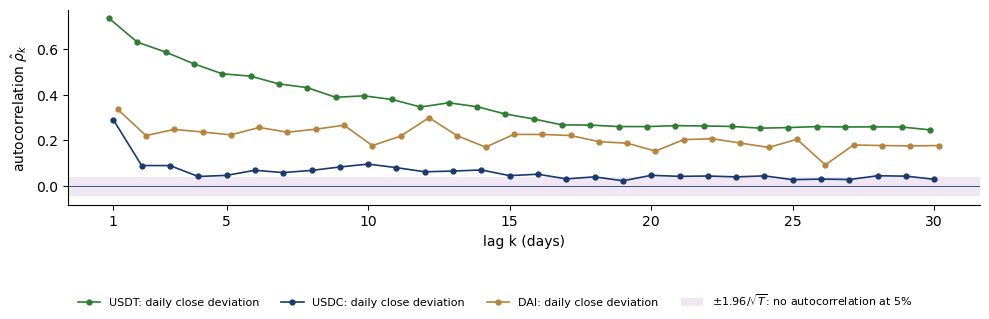

In [6]:
lags = np.arange(1, 31)
acf = pd.DataFrame({s: [dv[s].autocorr(k) for k in lags] for s in dv}, index=lags)
band = 1.96 / np.sqrt(len(dv))
fig, ax = plt.subplots(figsize=(10, 3.2))
for j, s in enumerate(dv):
    ax.plot(lags + (j - 1) * 0.15, acf[s], marker='o', ms=3.5, lw=1.2, color=COL[s], label=f'{s}: daily close deviation')
ax.axhspan(-band, band, color=ETH, alpha=0.15, lw=0, label=r'$\pm 1.96/\sqrt{T}$: no autocorrelation at 5%')
ax.axhline(0, color=BLUE, lw=0.6)
ax.set_xlabel('lag k (days)'); ax.set_ylabel(r'autocorrelation $\hat\rho_k$'); ax.set_xticks([1, 5, 10, 15, 20, 25, 30])
save(fig, 'ba_l5_acf', 0.16, ncol=4)

## Key numbers

In [7]:
print(f'T = {len(dv)} days; band +-{band:.3f}')
r1 = acf.loc[1, 'USDT']
print(f'USDT as an AR(1): half-life ln 0.5 / ln {r1:.2f} = {np.log(0.5) / np.log(r1):.1f} days; implied rho_30 = {r1 ** 30:.5f}, observed {acf.loc[30, "USDT"]:.2f}')
acf.loc[[1, 2, 7, 30]].round(2)

T = 2122 days; band +-0.043
USDT as an AR(1): half-life ln 0.5 / ln 0.73 = 2.2 days; implied rho_30 = 0.00008, observed 0.25


,USDT,USDC,DAI
1,0.73,0.29,0.34
2,0.63,0.09,0.22
7,0.45,0.06,0.24
30,0.25,0.03,0.18


**How to read it:** USDT deviations persist for weeks ($\hat\rho_{30} = 0.25$, while an AR(1) with $\rho = 0.73$ would give about 0.0001): its level shifts slowly.
USDC deviations close within a day or two ($\hat\rho_2 = 0.09$); DAI keeps a plateau near 0.2.